# Outlier Strategy Comparison

Compare interval-local legacy filtering with shot-wide local statistical filtering for one AUG shot and interval. Both branches use the same full-shot mapping and fitting settings; only the statistical outlier scope differs.

In [1]:
import copy
import sys
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
import importlib
import pandas as pd
import numpy as np
import yaml
from IPython.display import display

current_path = Path.cwd().resolve()
search_roots = [current_path, *current_path.parents, current_path / 'TS_profile_fitter']
project_root = next(
    (path for path in search_roots if (path / 'src' / 'ts_profile_fitter').is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not locate the TS_profile_fitter project root.')
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(project_root.parent / 'aug_separatrix'))
import get_connection_length_selectable as aug_connection_length
importlib.reload(aug_connection_length)
get_LcSOL = aug_connection_length.get_LcSOL

from ipfnpytools.plot import use_base_style
from ts_profile_fitter.loading import load_intervals, load_ts_data
from ts_profile_fitter.plotting import plot_profile_fit
import ts_profile_fitter.preprocess as preprocess
importlib.reload(preprocess)
import ts_profile_fitter.pipeline as pipeline
importlib.reload(pipeline)
from ts_profile_fitter.pipeline import run_interval
from ts_profile_fitter.preprocess import preprocess_ts_data

use_base_style()
new_config_path = project_root / 'configs' / 'pipeline_config_run05_new_outlier.yaml'
legacy_config_path = project_root / 'configs' / 'config_with_inner_core.yaml'
with new_config_path.open('r', encoding='utf-8') as config_file:
    new_pipeline_config = yaml.safe_load(config_file) or {}
with legacy_config_path.open('r', encoding='utf-8') as config_file:
    legacy_pipeline_config = yaml.safe_load(config_file) or {}


def resolve_config_path(config, key, default):
    path = Path(config.get(key, default))
    return path if path.is_absolute() else new_config_path.parent / path


new_fit_config = copy.deepcopy(new_pipeline_config['fit_config'])
legacy_fit_config = copy.deepcopy(legacy_pipeline_config['fit_config'])
new_preprocess_config = new_fit_config['preprocess']
legacy_preprocess_config = legacy_fit_config['preprocess']
local_statistical_config = new_preprocess_config.get('local_statistical_outlier_config')
if not local_statistical_config or not local_statistical_config.get('enabled', True):
    raise ValueError('The new-outlier configuration must enable local statistical filtering.')

# Use one shared mapping so the comparison isolates the configured filters.
mapping_method = legacy_preprocess_config.get('mapping_method', 'ipfnpytools')
r_edge_offset = legacy_preprocess_config.get('r_edge_offset', 0.008)
data_directory = resolve_config_path(new_pipeline_config, 'data_dir', '../data')
intervals_path = resolve_config_path(new_pipeline_config, 'database', '../data/intervals.csv')
equilibrium = legacy_pipeline_config.get('equilibrium', 'EQH')
diagnostic = legacy_pipeline_config.get('diagnostic', 'VTA')

shot_id = 36151
time_requested = 4.8
output_directory = project_root / 'plots'
save_figures = False
show_figures = True
close_figures = False

18:16:36 | aug_sfutils | INFO: Using version 0.9.3
18:16:36 | aug_sfutils.mapeq | INFO: AUG-SF home /shares/software/aug-dv/moduledata/aug_sfutils/0.9.3/aug_sfutils


In [2]:
intervals_df = load_intervals(str(intervals_path))
matching_intervals = intervals_df.loc[
    intervals_df['shot_id'].eq(shot_id)
    & intervals_df['t_begin'].le(time_requested)
    & intervals_df['t_end'].ge(time_requested)
]
if matching_intervals.empty:
    raise ValueError(
        f'No interval found for shot {shot_id} at t={time_requested:.3f} s.'
    )

selected_interval = matching_intervals.iloc[0]
interval = {
    't_begin': float(selected_interval['t_begin']),
    't_end': float(selected_interval['t_end']),
    'label': selected_interval['label'],
}
interval_begin = interval['t_begin']
interval_end = interval['t_end']

ts_data = load_ts_data(
    shot_id,
    str(data_directory),
    diagnostic=diagnostic,
    equilibrium=equilibrium,
)

mapped_shot = preprocess_ts_data(
    ts_data,
    interval=None,
    r_edge_offset=r_edge_offset,
    mapping_method=mapping_method,
    apply_filters=False,
)
mapped_shot['_comparison_row_id'] = range(len(mapped_shot))

print(
    f'Shot {shot_id} at {time_requested:.3f} s -> '
    f'interval [{interval_begin:.3f}, {interval_end:.3f}] s ({interval["label"]})'
)
print(f'Mapped full-shot measurements: {len(mapped_shot):,}')

18:16:37 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/VTA/36/36151.1
18:16:37 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/36/36151.1
18:16:37 | aug_sfutils.sf2equ | INFO: Reading equ scalars
18:16:37 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
18:16:38 | aug_sfutils.sf2equ | INFO: Reading equ PFM
18:16:38 | aug_sfutils.sf2equ | INFO: COCO 17


Dimensions before mapping: time: (982, 1) r: (982, 1) z: (1, 16)
Dimensions before mapping: time: (1307, 1) r: (1307, 1) z: (1, 11)


/u/joanune/ipfnpytools/ipfnpytools/trz_to_rhop.py:61: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), dtype=np.float32),
/u/joanune/ipfnpytools/ipfnpytools/trhopz_to_r.py:124: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.swapaxes(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), 0, 2), dtype=data_type),


Shot 36151 at 4.800 s -> interval [4.785, 4.893] s (developed pulsating EDA H-mode (with QCM))
Mapped full-shot measurements: 16,329


In [3]:
new_fit_config['fits']

{'mtanh': {'Te': {'deg_tail': 1,
   'deg_top': 3,
   'fix_a_tail': 0,
   'y_scale': '1.0e3'},
  'Ne': {'deg_tail': 1, 'deg_top': 3, 'y_scale': '1.0e19'}},
 'spline': {'method': 'ipfn_spline',
  'knot_strategy': 'edge_biased_quantile',
  'knot_count_shift': 4,
  'dR_fine': 0.002,
  'sigma_conv': 0.0,
  'dR_channel_max': 0.003,
  'ne_scale': 1e+19,
  'Te_scale': 1000.0,
  'max_step_scale': 3,
  'use_errors': True,
  's_factor': 1.0,
  'mono': 'decreasing',
  'maxiter': 500}}

In [4]:
#new_fit_config['fits']['spline']['knot_strategy'] = 'balanced_quantile'
#new_fit_config['fits']['spline']['knot_count_shift'] = 0
#new_fit_config.setdefault('physics', {}).setdefault('connection_length', {})['plot'] = True

#new_fit_config['fits']['spline']['knot_strategy'], new_fit_config['fits']['spline']['knot_count_shift']

In [5]:
pwd

'/shares/users/work/joanune/Desktop/TS_profile_fitter/notebooks'

In [6]:
legacy_diagnostics = {}
legacy_filter_log = StringIO()
with redirect_stdout(legacy_filter_log):
    legacy_result = run_interval(
        shot_id,
        interval,
        ts_data,
        fit_config=legacy_fit_config,
        make_plots=False,
        diagnostic_context=legacy_diagnostics,
        mapped_shot_data=mapped_shot,
    )

new_diagnostics = {}
new_filter_log = StringIO()
with redirect_stdout(new_filter_log):
    new_result = run_interval(
        shot_id,
        interval,
        ts_data,
        fit_config=new_fit_config,
        make_plots=False,
        diagnostic_context=new_diagnostics,
        mapped_shot_data=mapped_shot,
        connection_length_provider=get_LcSOL,
    )

print('Both YAML-configured filtering and fitting runs completed.')

18:16:54 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/36/36151.1
18:16:54 | aug_sfutils.sf2equ | INFO: Reading equ scalars
18:16:54 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
18:16:55 | aug_sfutils.sf2equ | INFO: Reading equ PFM
18:16:55 | aug_sfutils.sf2equ | INFO: COCO 17
18:16:56 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TTH/36/36151.1
18:16:56 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/davidp/BPT/36/36151.2
18:16:56 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TOT/36/36151.1
18:16:56 | aug_sfutils.sfread | ERROR: Shotfile not found for AUGD:ELM(0) #36151
18:16:57 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/36/36151.1
18:16:57 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/FPC/36/36151.1
18:16:57 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug

Both YAML-configured filtering and fitting runs completed.


In [7]:
insufficient_support_rows = new_diagnostics[
    'local_statistical_outlier_metadata'
].get('insufficient_support_rows')
if insufficient_support_rows is None:
    raise RuntimeError('The statistical filter did not return support diagnostics.')

if insufficient_support_rows.empty:
    print('No measurements in this interval were skipped for insufficient support.')
else:
    support_summary = (
        insufficient_support_rows
        .groupby(['system', 'quantity', 'metric', 'reason'], dropna=False)
        .agg(
            skipped_checks=('row_index', 'size'),
            distinct_points=('row_index', 'nunique'),
            min_valid_neighbors=('neighbor_count', 'min'),
            max_valid_neighbors=('neighbor_count', 'max'),
            min_radial_support=('radial_support', 'min'),
            min_temporal_support=('temporal_support', 'min'),
        )
        .reset_index()
    )
    display(support_summary)
    display(insufficient_support_rows.sort_values(
        ['time', 'system', 'channel_index', 'quantity', 'metric']
    ).reset_index(drop=True))

No measurements in this interval were skipped for insufficient support.


In [8]:
import ts_profile_fitter.plotting as plotting
importlib.reload(plotting)
plot_profile_fit = plotting.plot_profile_fit
raw_interval = mapped_shot.loc[
    mapped_shot['time'].between(interval_begin, interval_end)
].copy()


def rejected_interval_rows(result):
    retained = result['_mapped']
    retained_ids = retained['_comparison_row_id'].astype(int)
    rejected = raw_interval.loc[
        ~raw_interval['_comparison_row_id'].isin(retained_ids)
    ].copy()
    if len(retained) + len(rejected) != len(raw_interval):
        raise RuntimeError('Retained and rejected rows do not partition the interval input.')
    return rejected


legacy_rejected_rows = rejected_interval_rows(legacy_result)
new_rejected_rows = rejected_interval_rows(new_result)
profile_runs = {
    'Legacy: config_with_inner_core': {
        'result': legacy_result,
        'rejected': legacy_rejected_rows,
    },
    'Shot-wide: run05 statistical': {
        'result': new_result,
        'rejected': new_rejected_rows,
    },
}

comparison_summary = pd.DataFrame([
    {
        'strategy': strategy_name,
        'interval input points': len(raw_interval),
        'removed points': len(strategy_data['rejected']),
        'removed core points': int(strategy_data['rejected']['system'].eq('core').sum()),
        'removed edge points': int(strategy_data['rejected']['system'].eq('edge').sum()),
        'retained points': len(strategy_data['result']['_mapped']),
    }
    for strategy_name, strategy_data in profile_runs.items()
]).set_index('strategy')
display(comparison_summary)

,interval input points,removed points,removed core points,removed edge points,retained points
strategy,,,,,
Legacy: config_with_inner_core,228,37,12,25,191
Shot-wide: run05 statistical,228,37,12,25,191


In [9]:
from ts_profile_fitter.plotting import (
    plot_filtered_profile_with_outliers,
    PROFILE_RADIUS_LABEL,
)

profile_runs['Legacy: config_with_inner_core']['diagnostics'] = legacy_diagnostics
profile_runs['Shot-wide: run05 statistical']['diagnostics'] = new_diagnostics
origin_strategy_name = 'Shot-wide: run05 statistical'

## Rejected Measurements by Reason

Counts and point-level values are listed for each recorded filter reason. Filter `outliers_by_reason` by `outlier_reason` to inspect a family with the existing profile plot functions.

In [10]:
reasoned_frames = []
preprocess_removed = new_diagnostics.get('preprocess_removed_rows')
if preprocess_removed is not None and not preprocess_removed.empty:
    reasoned_frames.append(preprocess_removed)

for metadata_key in (
    'local_statistical_outlier_metadata',
    'density_outside_separatrix_metadata',
    'cold_dense_edge_metadata',
    'distance_outlier_metadata',
):
    stage_metadata = new_diagnostics.get(metadata_key)
    if stage_metadata is not None:
        stage_removed = stage_metadata.get('removed_rows')
        if stage_removed is not None and not stage_removed.empty:
            reasoned_frames.append(stage_removed)

if reasoned_frames:
    reasoned_outliers = pd.concat(reasoned_frames, ignore_index=True)
else:
    reasoned_outliers = new_rejected_rows.head(0).copy()
    reasoned_outliers['filter_reason'] = pd.Series(dtype=str)

rejected_ids = set(new_rejected_rows['_comparison_row_id'])
reasoned_outliers = reasoned_outliers.loc[
    reasoned_outliers['_comparison_row_id'].isin(rejected_ids)
].drop_duplicates(['_comparison_row_id', 'filter_reason'])
reasoned_outliers['outlier_reason'] = (
    reasoned_outliers['filter_reason'].fillna('').str.split(';'))
outliers_by_reason = reasoned_outliers.explode('outlier_reason')
outliers_by_reason['outlier_reason'] = (
    outliers_by_reason['outlier_reason'].astype(str).str.strip())
outliers_by_reason = outliers_by_reason.loc[
    outliers_by_reason['outlier_reason'].ne('')
].copy()

reasoned_ids = set(outliers_by_reason['_comparison_row_id'])
missing_reason_ids = rejected_ids - reasoned_ids
unreasoned_outliers = new_rejected_rows.loc[
    new_rejected_rows['_comparison_row_id'].isin(missing_reason_ids)
].copy()

reason_summary = outliers_by_reason.groupby('outlier_reason').agg(
    points=('_comparison_row_id', 'nunique'),
    core=('system', lambda values: values.eq('core').sum()),
    edge=('system', lambda values: values.eq('edge').sum()),
).sort_values('points', ascending=False)
display(reason_summary)

reason_detail_columns = [
    column for column in (
        '_comparison_row_id', 'shot', 'system', 'channel_index', 'time',
        'r_midplane', 'Te', 'Te_err', 'Ne', 'Ne_err', 'outlier_reason',
    )
    if column in outliers_by_reason.columns
]
display(
    outliers_by_reason[reason_detail_columns]
    .sort_values(['outlier_reason', 'time', 'system', 'channel_index'])
    .reset_index(drop=True)
)

if not unreasoned_outliers.empty:
    print(
        f'{len(unreasoned_outliers)} rejected measurements have no recorded '
        'filter reason in the captured stage metadata:'
    )
    unreasoned_columns = [
        column for column in (
            '_comparison_row_id', 'shot', 'system', 'channel_index', 'time',
            'r_midplane', 'rho_pol', 'Te', 'Te_err', 'Ne', 'Ne_err',
        )
        if column in unreasoned_outliers.columns
    ]
    display(
        unreasoned_outliers[unreasoned_columns]
        .sort_values(['time', 'system', 'channel_index'])
        .reset_index(drop=True)
    )

,points,core,edge
outlier_reason,,,
Te_statistical_upper_value_outlier,16,0,16
Ne_outlier,6,0,6
Ne_zero_error,5,0,5
Te_zero_value,5,0,5
Te_zero_error,5,0,5
Te_outlier,5,0,5
Ne_zero_value,5,0,5
Ne_statistical_upper_value_outlier,3,0,3
Ne_negative_value,1,0,1


,_comparison_row_id,system,channel_index,time,r_midplane,Te,Te_err,Ne,Ne_err,outlier_reason
0,13237,edge,10,4.876551,2.195012,144.587646,131.112885,-1.279501e+18,7.910935e+17,Ne_negative_value
1,13152,edge,2,4.817662,2.175238,0.000000,0.000000,0.000000e+00,0.000000e+00,Ne_outlier
2,13193,edge,10,4.843162,2.200467,0.000000,0.000000,0.000000e+00,0.000000e+00,Ne_outlier
3,13214,edge,9,4.859661,2.163646,0.000000,0.000000,0.000000e+00,0.000000e+00,Ne_outlier
4,13215,edge,10,4.859661,2.189284,0.000000,0.000000,0.000000e+00,0.000000e+00,Ne_outlier
5,13216,edge,0,4.867656,2.229787,0.000000,0.000000,0.000000e+00,0.000000e+00,Ne_outlier
6,13237,edge,10,4.876551,2.195012,144.587646,131.112885,-1.279501e+18,7.910935e+17,Ne_outlier
7,13182,edge,10,4.834862,2.197467,1.260376,103.623001,7.577255e+21,3.937674e+24,Ne_statistical_relative_error_outlier
8,13182,edge,10,4.834862,2.197467,1.260376,103.623001,7.577255e+21,3.937674e+24,Ne_statistical_upper_value_outlier
9,13184,edge,1,4.843162,2.207422,1.000468,0.001013,4.184499e+20,1.572813e+17,Ne_statistical_upper_value_outlier


12 rejected measurements have no recorded filter reason in the captured stage metadata:


,_comparison_row_id,system,channel_index,time,r_midplane,rho_pol,Te,Te_err,Ne,Ne_err
0,4558,core,14,4.807303,2.133507,0.988483,191.594894,14.011192,6.207670e+19,2.849910e+18
1,4559,core,15,4.807303,2.164191,1.040205,62.775291,33.608700,7.632639e+18,2.229894e+18
2,4574,core,14,4.815663,2.135417,0.991802,234.014709,7.790871,6.523767e+19,2.182464e+18
3,4575,core,15,4.815663,2.166101,1.042949,6.272093,4.993681,2.619400e+19,2.517343e+19
4,4590,core,14,4.823923,2.137053,0.991477,197.843246,7.715666,6.622082e+19,3.042304e+18
5,4591,core,15,4.823923,2.168010,1.043364,14.411839,20.943279,1.432909e+19,1.005159e+19
6,4606,core,14,4.857296,2.134462,0.989640,215.109604,9.977930,6.995831e+19,3.075462e+18
7,4607,core,15,4.857296,2.165010,1.041055,13.244049,17.397207,1.483630e+19,1.055365e+19
8,4622,core,14,4.865656,2.135689,0.992346,224.539230,10.574548,5.976136e+19,2.378951e+18
9,4623,core,15,4.865656,2.166373,1.043854,700.624207,427.565979,7.680259e+18,2.297012e+18


In [11]:
reason_tags_by_row = reasoned_outliers.groupby('_comparison_row_id')['filter_reason'].agg(
    lambda values: '; '.join(dict.fromkeys(
        tag.strip()
        for value in values.dropna().astype(str)
        for tag in value.split(';')
        if tag.strip()
    ))
)
outliers_with_reasons = new_rejected_rows.merge(
    reason_tags_by_row.rename('filter_reason'),
    how='left',
    left_on='_comparison_row_id',
    right_index=True,
)
outliers_with_reasons['filter_reason'] = (
    outliers_with_reasons['filter_reason'].fillna(''))

## Filtered Profile and Outliers

Filtered measurements are colored by time. Outlier markers are grouped as `Negative or zero`, `core channel removal`, `Other`, `Te_stat`, and `Ne_stat` by their recorded `filter_reason`.

/tmp/ipykernel_74074/1523865345.py:1: UserWarning: not plotting dataset 1 due to ValueError: ('zero-size array to reduction operation fmax which has no identity',)
  plot_filtered_profile_with_outliers(
/tmp/ipykernel_74074/1523865345.py:1: UserWarning: not plotting dataset 9 due to ValueError: ('zero-size array to reduction operation fmax which has no identity',)
  plot_filtered_profile_with_outliers(


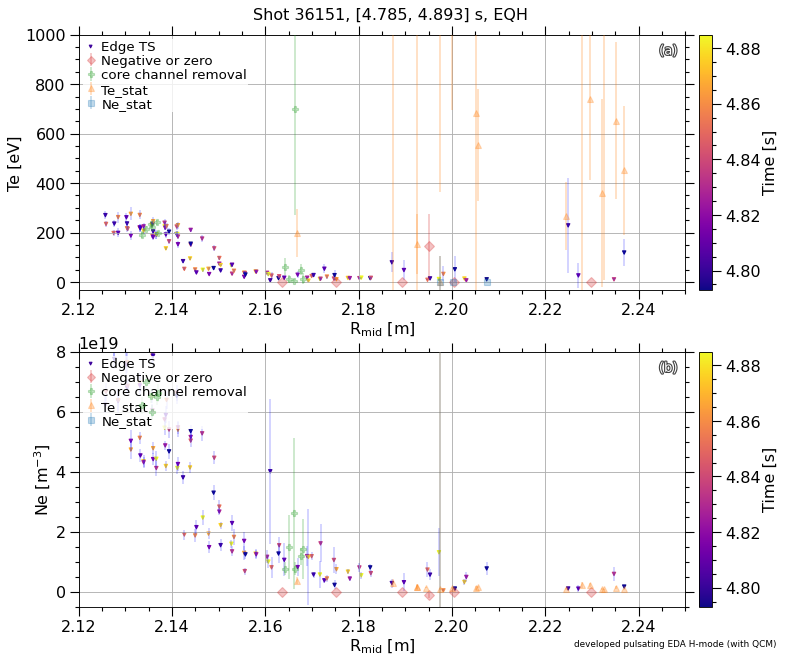

(<Figure size 803.15x661.832 with 4 Axes>,
 array([<Axes: xlabel='$R_{\\mathrm{mid}}$ [m]', ylabel='Te [eV]'>,
        <Axes: xlabel='$R_{\\mathrm{mid}}$ [m]', ylabel='Ne [m$^{-3}$]'>],
       dtype=object))

In [12]:
plot_filtered_profile_with_outliers(
    filtered=new_result['_mapped'],
    outliers=outliers_with_reasons,
    quantity=('Te', 'Ne'),
    #directory=str(output_directory),
    save_fig=False,
    directory = '/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Data_Processing/figures',
    show=show_figures,
    close=close_figures,
    nshot=shot_id,
    interval=interval,
    equilibrium=equilibrium,
    fig_name=f'{shot_id}_shot_wide_te_ne_filtered_outliers',
    y_mins_boxes=[-30, -5e18],
    y_maxs_boxes=[1000, 0.8e20],
    x_mins=2.12,
    x_maxs=2.25,
    h_factor=1.5,
    v_factor=2
)

In [13]:
radius_window = (2.22, 2.24)
nearby_Te_flags = outliers_with_reasons.loc[
    outliers_with_reasons['r_midplane'].between(*radius_window)
    & outliers_with_reasons['filter_reason'].str.contains(
        'Te_statistical_', na=False)
].copy()
nearby_Te_flags['Te_relative_error'] = (
    nearby_Te_flags['Te_err'] / nearby_Te_flags['Te'].abs())
nearby_Te_columns = [
    column for column in (
        '_comparison_row_id', 'system', 'channel_index', 'time', 'r_midplane',
        'Te', 'Te_err', 'Te_relative_error', 'filter_reason',
    )
    if column in nearby_Te_flags.columns
]
display(
    nearby_Te_flags[nearby_Te_columns]
    .sort_values(['r_midplane', 'time'])
    .reset_index(drop=True)
)

from ts_profile_fitter.preprocess import (
    _apply_channel_trim,
    _apply_measurement_validity_filters,
    _apply_rhop_filter,
)

active_preprocess_config = new_fit_config['preprocess']
local_filter_config = active_preprocess_config['local_statistical_outlier_config']
default_threshold = float(local_filter_config.get('threshold', 3.5))
upper_value_threshold = float(
    local_filter_config.get('upper_value_threshold', default_threshold))
relative_error_threshold = float(
    local_filter_config.get('relative_error_threshold', default_threshold))
support_data, _ = _apply_measurement_validity_filters(
    mapped_shot, return_metadata=True)
support_data = _apply_rhop_filter(
    support_data, rhop_filter=active_preprocess_config.get('rhop_filter'))
support_data = _apply_channel_trim(
    support_data, channel_trim=active_preprocess_config.get('channel_trim'))


def _neighborhood_cutoff(values, threshold):
    values = pd.to_numeric(values, errors='coerce').to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return 0, np.nan, np.nan, np.nan
    median = float(np.median(values))
    mad = float(np.median(np.abs(values - median)))
    cutoff = median + threshold * 1.4826 * mad
    return int(values.size), median, mad, float(cutoff)


neighborhood_summaries = []
neighborhood_rows = []
for _, target in nearby_Te_flags.iterrows():
    target_id = int(target['_comparison_row_id'])
    system_data = support_data.loc[
        support_data['system'].eq(target['system'])]
    radial_width = local_filter_config['radial_half_width_m'][target['system']]
    time_width = float(local_filter_config['time_half_width_s'])
    radial_delta = np.abs(system_data['r_midplane'] - target['r_midplane'])
    time_delta = np.abs(system_data['time'] - target['time'])
    neighbors = system_data.loc[
        radial_delta.le(radial_width)
        & time_delta.le(time_width)
        & system_data['_comparison_row_id'].ne(target_id)
    ].copy()

    if 'channel_index' in support_data.columns and pd.notna(target['channel_index']):
        spatial_channels = set(neighbors['channel_index'].dropna())
        spatial_channels.add(target['channel_index'])
        required_channels = max(
            int(local_filter_config.get('min_radial_neighbors', 2)), 2)
        channels_to_add = max(0, required_channels - len(spatial_channels))
        if channels_to_add:
            radial_column = (
                'rho_pol' if 'rho_pol' in support_data.columns else 'r_midplane')
            temporal = system_data.loc[time_delta.le(time_width)]
            candidates = temporal.loc[
                temporal['channel_index'].notna()
                & ~temporal['channel_index'].isin(spatial_channels)
            ].copy()
            candidates['_radial_distance'] = np.abs(
                candidates[radial_column] - target[radial_column])
            channel_distances = candidates.groupby(
                'channel_index')['_radial_distance'].median()
            nearest_channels = channel_distances.nsmallest(channels_to_add).index
            fallback_rows = temporal.loc[
                temporal['channel_index'].isin(nearest_channels)]
            neighbors = pd.concat([neighbors, fallback_rows]).drop_duplicates(
                '_comparison_row_id')

    neighbor_density = neighbors['Te']
    neighbor_relative_error = (
        neighbors['Te_err'] / neighbors['Te'].abs())
    n_density, density_median, density_mad, density_cutoff = (
        _neighborhood_cutoff(neighbor_density, upper_value_threshold))
    n_relerr, relerr_median, relerr_mad, relerr_cutoff = (
        _neighborhood_cutoff(
            neighbor_relative_error, relative_error_threshold))
    neighborhood_summaries.append({
        '_comparison_row_id': target_id,
        'time': target['time'],
        'r_midplane': target['r_midplane'],
        'Te': target['Te'],
        'Te_relative_error': target['Te_relative_error'],
        'neighbor_count': n_relerr,
        'neighbor_channels': neighbors['channel_index'].nunique(),
        'Te_neighbor_median': density_median,
        'Te_neighbor_MAD': density_mad,
        'Te_upper_value_cutoff': density_cutoff,
        'relative_error_neighbor_median': relerr_median,
        'relative_error_neighbor_MAD': relerr_mad,
        'relative_error_cutoff': relerr_cutoff,
        'reason': target['filter_reason'],
    })
    neighbor_view = neighbors.assign(
        _target_row_id=target_id,
        Te_relative_error=neighbor_relative_error,
        rejected_in_interval=neighbors['_comparison_row_id'].isin(
            set(new_rejected_rows['_comparison_row_id'])),
    )
    neighborhood_rows.append(neighbor_view[[
        '_target_row_id', '_comparison_row_id', 'channel_index', 'time',
        'r_midplane', 'Te', 'Te_err', 'Te_relative_error',
        'rejected_in_interval',
    ]])

display(pd.DataFrame(neighborhood_summaries))

,_comparison_row_id,system,channel_index,time,r_midplane,Te,Te_err,Te_relative_error,filter_reason
0,13194,edge,0,4.851656,2.224332,267.174286,136.379074,0.510450,Te_statistical_upper_value_outlier
1,13205,edge,0,4.859661,2.227741,6258.566895,12569.385742,2.008349,Te_statistical_upper_value_outlier
2,13150,edge,0,4.817662,2.229650,738.383118,325.569672,0.440922,Te_statistical_upper_value_outlier
3,13227,edge,0,4.876551,2.232105,359.114502,379.953766,1.058030,Te_statistical_upper_value_outlier
4,13161,edge,0,4.826557,2.232514,2918.711670,2911.049072,0.997375,Te_statistical_upper_value_outlier
5,13238,edge,0,4.884856,2.235106,652.668579,317.834991,0.486978,Te_statistical_upper_value_outlier
6,13183,edge,0,4.843162,2.236878,452.068329,261.443848,0.578328,Te_statistical_upper_value_outlier


,_comparison_row_id,time,r_midplane,Te,Te_relative_error,neighbor_count,neighbor_channels,Te_neighbor_median,Te_neighbor_MAD,Te_upper_value_cutoff,relative_error_neighbor_median,relative_error_neighbor_MAD,relative_error_cutoff,reason
0,13150,4.817662,2.229650,738.383118,0.440922,17,3,79.855095,72.882992,620.136713,0.791102,0.371744,9.058312,Te_statistical_upper_value_outlier
1,13161,4.826557,2.232514,2918.711670,0.997375,16,3,154.509197,153.378775,1291.506055,0.543206,0.265280,6.442767,Te_statistical_upper_value_outlier
2,13183,4.843162,2.236878,452.068329,0.578328,13,3,33.076050,32.075585,270.852358,0.779178,0.517129,12.279602,Te_statistical_upper_value_outlier
3,13194,4.851656,2.224332,267.174286,0.510450,11,3,33.076050,32.075585,270.852358,0.924088,0.662038,15.647160,Te_statistical_upper_value_outlier
4,13205,4.859661,2.227741,6258.566895,2.008349,13,3,33.076050,32.075585,270.852358,0.578328,0.345760,8.267681,Te_statistical_upper_value_outlier
5,13227,4.876551,2.232105,359.114502,1.058030,13,3,33.076050,32.075585,270.852358,0.490004,0.227955,5.559491,Te_statistical_upper_value_outlier
6,13238,4.884856,2.235106,652.668579,0.486978,12,3,12.989117,11.858629,100.897135,0.495229,0.280818,6.740346,Te_statistical_upper_value_outlier


In [14]:
retained_high_te = new_result['_mapped'].loc[
    new_result['_mapped']['system'].eq('edge')
    & new_result['_mapped']['r_midplane'].between(*radius_window)
    & new_result['_mapped']['Te'].gt(600)
].copy()

candidate_cutoffs = []
for _, target in retained_high_te.iterrows():
    target_id = target['_comparison_row_id']
    candidate_support = support_data.loc[
        support_data['system'].eq(target['system'])
    ].copy()
    if 'shot' in support_data.columns and pd.notna(target.get('shot')):
        candidate_support = candidate_support.loc[
            candidate_support['shot'].eq(target['shot'])]

    radial_width = local_filter_config['radial_half_width_m'][target['system']]
    time_width = float(local_filter_config['time_half_width_s'])
    radial_delta = np.abs(
        candidate_support['r_midplane'] - target['r_midplane'])
    time_delta = np.abs(candidate_support['time'] - target['time'])
    neighbors = candidate_support.loc[
        radial_delta.le(radial_width)
        & time_delta.le(time_width)
        & candidate_support['_comparison_row_id'].ne(target_id)
    ].copy()

    if 'channel_index' in support_data.columns and pd.notna(target['channel_index']):
        spatial_channels = set(neighbors['channel_index'].dropna())
        spatial_channels.add(target['channel_index'])
        required_channels = max(
            int(local_filter_config.get('min_radial_neighbors', 2)), 2)
        channels_to_add = max(0, required_channels - len(spatial_channels))
        if channels_to_add:
            radial_column = (
                'rho_pol' if 'rho_pol' in support_data.columns else 'r_midplane')
            temporal = candidate_support.loc[time_delta.le(time_width)]
            fallback_candidates = temporal.loc[
                temporal['channel_index'].notna()
                & ~temporal['channel_index'].isin(spatial_channels)
            ].copy()
            fallback_candidates['_radial_distance'] = np.abs(
                fallback_candidates[radial_column] - target[radial_column])
            channel_distances = fallback_candidates.groupby(
                'channel_index')['_radial_distance'].median()
            nearest_channels = channel_distances.nsmallest(channels_to_add).index
            fallback_rows = temporal.loc[
                temporal['channel_index'].isin(nearest_channels)]
            neighbors = pd.concat([neighbors, fallback_rows]).drop_duplicates(
                '_comparison_row_id')

    neighbor_values = pd.to_numeric(neighbors['Te'], errors='coerce')
    valid_neighbors = neighbors.loc[np.isfinite(neighbor_values)].copy()
    values = neighbor_values.loc[valid_neighbors.index].to_numpy(dtype=float)
    median = float(np.median(values)) if values.size else np.nan
    mad = float(np.median(np.abs(values - median))) if values.size else np.nan
    cutoff = median + upper_value_threshold * 1.4826 * mad
    candidate_cutoffs.append({
        '_comparison_row_id': target_id,
        'time': target['time'],
        'r_midplane': target['r_midplane'],
        'Te': target['Te'],
        'Te_err': target['Te_err'],
        'neighbor_count': len(valid_neighbors),
        'neighbor_channels': valid_neighbors['channel_index'].nunique(),
        'neighbor_median': median,
        'neighbor_MAD': mad,
        'upper_value_threshold': upper_value_threshold,
        'computed_Te_cutoff': cutoff,
        'exceeds_cutoff': bool(target['Te'] > cutoff),
    })

display(pd.DataFrame(candidate_cutoffs))

""


In [15]:
candidate_neighbor_detail = neighbors.assign(
    Te_relative_error=neighbors['Te_err'] / neighbors['Te'].abs(),
    rejected_in_interval=neighbors['_comparison_row_id'].isin(
        set(new_rejected_rows['_comparison_row_id'])),
)[[
    '_comparison_row_id', 'channel_index', 'time', 'r_midplane',
    'Te', 'Te_err', 'Te_relative_error', 'rejected_in_interval',
]].sort_values(['Te', 'time'], ascending=[False, True])
display(candidate_neighbor_detail)

,_comparison_row_id,channel_index,time,r_midplane,Te,Te_err,Te_relative_error,rejected_in_interval
13239,13239,1,4.884856,2.205513,554.410889,227.060928,0.409554,True
13227,13227,0,4.876551,2.232105,359.114502,379.953766,1.058030,True
13226,13226,10,4.867656,2.192557,154.294601,120.223000,0.779178,True
13259,13259,10,4.893156,2.200330,27.722500,13.584146,0.490004,False
13228,13228,1,4.876551,2.202649,14.274459,3.454434,0.242001,False
13261,13261,1,4.901650,2.195012,13.658511,2.328659,0.170491,False
13248,13248,10,4.884856,2.197194,12.319723,6.165443,0.500453,False
13250,13250,1,4.893156,2.207422,11.215323,3.036116,0.270711,False
13272,13272,1,4.909655,2.197876,7.627152,5.895146,0.772916,False
13281,13281,10,4.909655,2.189693,1.260511,188.237335,149.334167,False


## Fitted Profiles Without Outlier Overlays

The first fit-quality plot shows the filtered Te and Ne profiles with modified-tanh fits. The following plots show the corresponding monotonic spline fits, with knot locations marked below the measurements.

Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Profile_Fitting/figures/shot36151_EQH_k00_t4p785-4p893_wide_te_ne_fit_quality.pdf


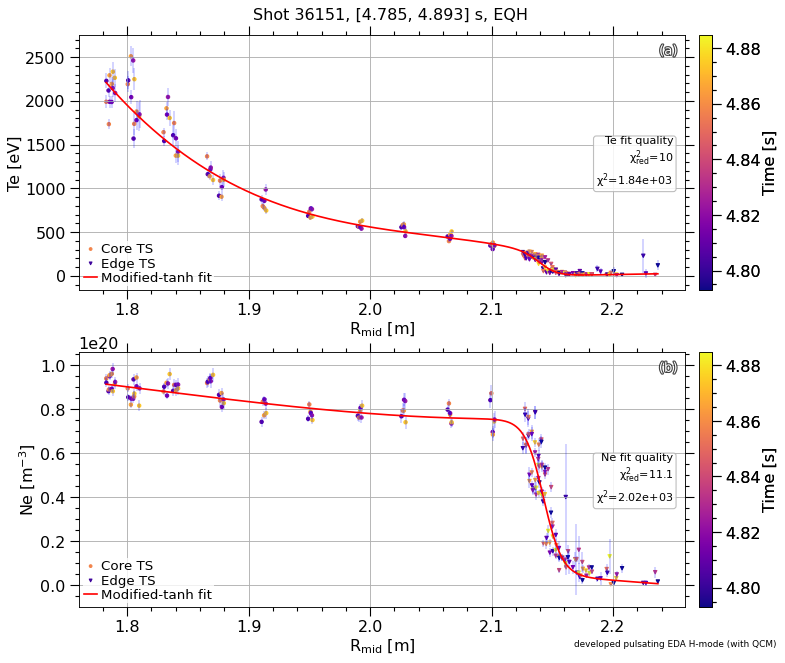

(<Figure size 803.15x661.832 with 6 Axes>,
 array([<Axes: xlabel='$R_{\\mathrm{mid}}$ [m]', ylabel='Te [eV]'>,
        <Axes: xlabel='$R_{\\mathrm{mid}}$ [m]', ylabel='Ne [m$^{-3}$]'>],
       dtype=object))

In [16]:
import importlib
import ts_profile_fitter.plotting as plotting
from ts_profile_fitter.figure_naming import make_fig_name
plotting = importlib.reload(plotting)
plot_filtered_profile_with_outliers = plotting.plot_filtered_profile_with_outliers

plot_filtered_profile_with_outliers(
    filtered=new_result['_mapped'],
    outliers=None,
    quantity=('Te', 'Ne'),
    directory='/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Profile_Fitting/figures',
    save_fig=True,
    show=show_figures,
    close=close_figures,
    nshot=shot_id,
    interval=interval,
    equilibrium=equilibrium,
    fig_name = make_fig_name(shot_id, equilibrium, interval = interval, n_knots = 0,plot_kind='wide_te_ne_fit_quality'),
    popt={
        quantity: new_result['mtanh'][quantity]['params']
        for quantity in ('Te', 'Ne')
    },
    fit_metrics=new_result['fit_metrics']['mtanh'],
    fit_metrics_loc='center right',
    show_fit=True,
    show_outliers=False,
    h_factor=1.5,
    v_factor=2.0,
    legend_kw={'loc': 'best'}
)

Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Profile_Fitting/figures/36151_shot_wide_te_ne_spline_fit_quality.pdf


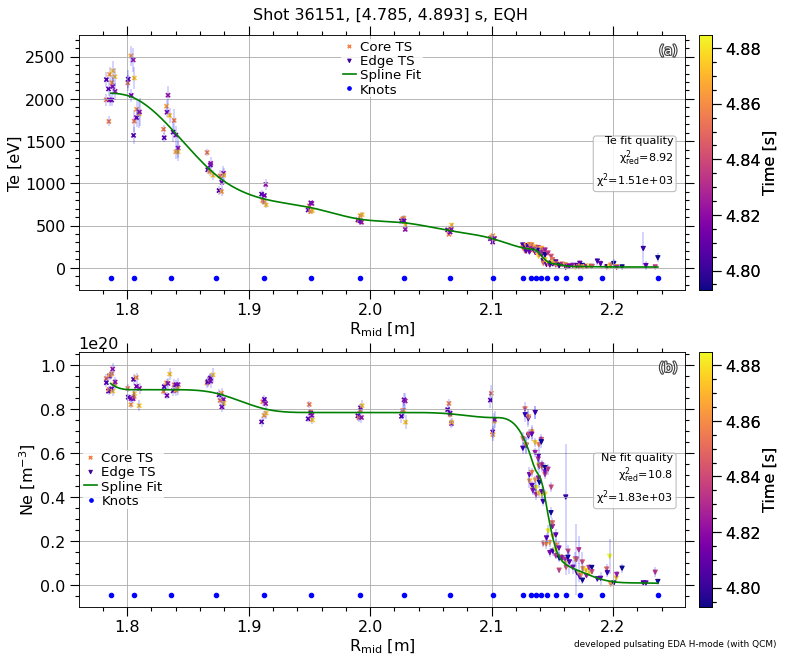

(<Figure size 803.15x661.832 with 6 Axes>,
 array([<Axes: xlabel='$R_{\\mathrm{mid}}$ [m]', ylabel='Te [eV]'>,
        <Axes: xlabel='$R_{\\mathrm{mid}}$ [m]', ylabel='Ne [m$^{-3}$]'>],
       dtype=object))

In [17]:
import importlib
plotting = importlib.reload(plotting)

spline_plot_data = new_result['_mapped']
spline_core = spline_plot_data.loc[spline_plot_data['system'].eq('core')]
spline_edge = spline_plot_data.loc[spline_plot_data['system'].eq('edge')]

plotting.plot_spline_profile_fit(
    x_core=spline_core['r_midplane'].to_numpy(),
    x_edge=spline_edge['r_midplane'].to_numpy(),
    y_core={
        quantity: spline_core[quantity].to_numpy()
        for quantity in ('Te', 'Ne')
    },
    y_edge={
        quantity: spline_edge[quantity].to_numpy()
        for quantity in ('Te', 'Ne')
    },
    y_err_core={
        quantity: spline_core[f'{quantity}_err'].to_numpy()
        for quantity in ('Te', 'Ne')
    },
    y_err_edge={
        quantity: spline_edge[f'{quantity}_err'].to_numpy()
        for quantity in ('Te', 'Ne')
    },
    ds_out=new_result['_ds_out'],
    quantity=('Te', 'Ne'),
    x_labels=PROFILE_RADIUS_LABEL,
    y_labels=['Te [eV]', 'Ne [m$^{-3}$]'],
    knot_pos=new_result['_knots'],
    time_c=spline_core['time'].to_numpy(),
    time_e=spline_edge['time'].to_numpy(),
    directory='/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Profile_Fitting/figures',
    close=close_figures,
    save_fig=True,
    show=show_figures,
    nshot=shot_id,
    interval=interval,
    equilibrium=equilibrium,
    fig_name=f'{shot_id}_shot_wide_te_ne_spline_fit_quality',
    fit_metrics=new_result['fit_metrics']['spline'],
    fit_metrics_loc='center right',
    h_factor=1.5,
    v_factor=2.0,
    legend_kw={'loc': 'best'},
)

Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Separatrix_Physics/figures/shot36151_EQH_k20_t4p785-4p893_profiles_and_qs_edge_biased_quantile.pdf


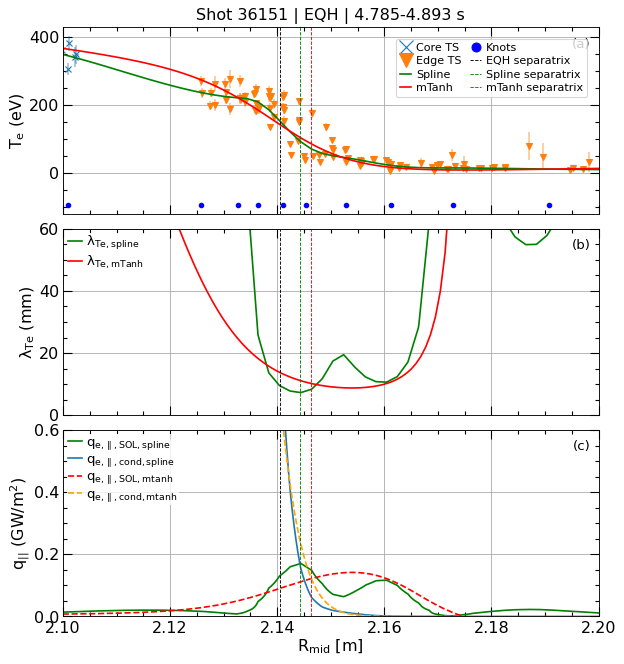

In [18]:
import numpy as np

mapped = new_result['_mapped']
core = mapped.loc[mapped['system'].eq('core')]
edge = mapped.loc[mapped['system'].eq('edge')]
ds_out = new_result['_ds_out']
physics_result = new_result['physics']
spline_physics = physics_result['spline']
mtanh_physics = physics_result['mtanh']

core_r = core['r_midplane'].to_numpy(dtype=float)
edge_r = edge['r_midplane'].to_numpy(dtype=float)
core_te = core['Te'].to_numpy(dtype=float)
edge_te = edge['Te'].to_numpy(dtype=float)
core_te_err = core['Te_err'].to_numpy(dtype=float)
edge_te_err = edge['Te_err'].to_numpy(dtype=float)

measured_r = np.concatenate([core_r, edge_r])
measured_r = measured_r[np.isfinite(measured_r)]
core_channels = np.sort(np.unique(core_r[np.isfinite(core_r)]))
#r_zoom_min = core_channels[-2] if core_channels.size >= 2 else np.nanmin(measured_r)
r_zoom_min=2.10
#r_zoom_max = np.nanmax(measured_r)
r_zoom_max=2.20

te_fit_r = np.linspace(np.nanmin(measured_r), np.nanmax(measured_r), 500)
te_mtanh = plotting.modified_tanh(
    te_fit_r, *np.asarray(new_result['mtanh']['Te']['params'], dtype=float)
)
spline_r = ds_out['R_mid_spl'].to_numpy(dtype=float)
te_spline = ds_out['Te_spl'].to_numpy(dtype=float)
te_measurements = np.concatenate([core_te, edge_te])
te_measurements = te_measurements[np.isfinite(te_measurements)]
knot_y = np.nanmin(te_measurements) - 0.04 * (np.ptp(te_measurements) or 1.0)
knots = np.asarray(new_result['_knots'], dtype=float)

spline_r_physics = np.asarray(spline_physics['R_grid'], dtype=float)
mtanh_r_physics = np.asarray(mtanh_physics['R_grid'], dtype=float)
spline_lambda = 1e3 * np.asarray(spline_physics['lam_Te_grid'], dtype=float)
mtanh_lambda = 1e3 * np.asarray(mtanh_physics['lam_Te_grid'], dtype=float)

x_data = [
    core_r, edge_r, core_r, edge_r, spline_r, te_fit_r, knots,
    spline_r_physics, mtanh_r_physics,
    spline_r_physics, spline_r_physics, mtanh_r_physics, mtanh_r_physics,
]
y_data = [
    core_te, edge_te, core_te, edge_te, te_spline, te_mtanh,
    np.full(knots.size, knot_y), spline_lambda, mtanh_lambda,
    1e-9 * np.asarray(spline_physics['q_par_P_SOL_grid'], dtype=float),
    1e-9 * np.asarray(spline_physics['q_par_SH_grid'], dtype=float),
    1e-9 * np.asarray(mtanh_physics['q_par_P_SOL_grid'], dtype=float),
    1e-9 * np.asarray(mtanh_physics['q_par_SH_grid'], dtype=float),
]
ey_data = [
    core_te_err, edge_te_err, None, None, None, None, None,
    None, None, None, None, None, None,
]
boxes = [0] * 7 + [1] * 2 + [2] * 4

labels = [
    None, None, 'Core TS', 'Edge TS', 'Spline', 'mTanh', 'Knots',
    r'$\lambda_{Te,\mathrm{spline}}$', r'$\lambda_{Te,\mathrm{mTanh}}$',
    r'$q_{e,\parallel,\mathrm{SOL,spline}}$', r'$q_{e,\parallel,\mathrm{cond,spline}}$',
    r'$q_{e,\parallel,\mathrm{SOL,mtanh}}$', r'$q_{e,\parallel,\mathrm{cond,mtanh}}$',
]
linestyles = ['', '', '', '', '-', '-', '', '-', '-', '-', '-', '--', '--']
markers = [None, None, 'x', 'v', None, None, 'o'] + [None] * 6
markersizes = [0, 0, 6, 6, None, None, 4] + [None] * 6
plot_kw = [
    {'color': 'tab:blue', 'ecolor': 'tab:blue', 'alpha': 0.45},
    {'color': 'tab:orange', 'ecolor': 'tab:orange', 'alpha': 0.45},
    {'color': 'tab:blue'}, {'color': 'tab:orange'},
    {'color': 'green'}, {'color': 'red'}, {'color': 'blue'},
    {'color': 'green'}, {'color': 'red'},
    {'color': 'green'}, {'color': 'tab:blue'},
    {'color': 'red'}, {'color': 'orange'},
]

ipfn_plots = plotting.ipfn_plots
fig, axes = ipfn_plots(
    x=x_data,
    y=y_data,
    ey=ey_data,
    boxes=boxes,
    nrows=3,
    ncols=1,
    order='column',
    labels=labels,
    linestyles=linestyles,
    markers=markers,
    markersizes=markersizes,
    plot_kw=plot_kw,
    x_labels=[None, None, PROFILE_RADIUS_LABEL],
    y_labels=['$T_e$', '$\\lambda_{Te}$', '$q_{||}$'],
    x_units_boxes=[None, None, 'm'],
    y_units_boxes=['eV', 'mm', 'GW/m$^2$'],
    x_mins_boxes=[r_zoom_min] * 3,
    x_maxs_boxes=[r_zoom_max] * 3,
    h_factor=1.3,
    v_factor=2.0,
    hspace=0.08,
    write_legends=True,
    title=f'Shot {shot_id} | {equilibrium} | {interval["t_begin"]:.3f}-{interval["t_end"]:.3f} s',
    show=False,
    close=False,
    save_fig=False,
)

axes = np.asarray(axes, dtype=object).reshape(-1)
for axis in axes[1:]:
    axis.sharex(axes[0])
for axis in axes:
    axis.set_xlim(r_zoom_min, r_zoom_max)
    for label, position, color in (
        ('EQH separatrix', physics_result['eqh']['Rsep_eqh'], 'black'),
        ('Spline separatrix', spline_physics['Rsep'], 'green'),
        ('mTanh separatrix', mtanh_physics['Rsep'], 'red'),
    ):
        axis.axvline(
            position, color=color, linestyle='--', linewidth=0.8,
            label=label if axis is axes[0] else None,
        )

eqh_rsep = float(physics_result['eqh']['Rsep_eqh'])
lambda_at_eqh = [
    np.interp(eqh_rsep, spline_r_physics, spline_lambda),
    np.interp(eqh_rsep, mtanh_r_physics, mtanh_lambda),
]
lambda_upper = np.nanmax(lambda_at_eqh)
lambda_upper += 0.05 * max(abs(lambda_upper), 1e-3)
axes[1].set_ylim(0, 60)
axes[2].set_ylim(0, 0.6)

for axis in axes[:-1]:
    axis.tick_params(axis='x', labelbottom=False)
axes[-1].set_xlabel(PROFILE_RADIUS_LABEL)
axes[0].legend(loc='upper right', ncol=2, fontsize=10)
from ipfnpytools.save_figure import save_figure
save_figure(fig,
             directory='/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Separatrix_Physics/figures',
             format='pdf', name =make_fig_name(shot_id, equilibrium, knots.size, interval, 'profiles_and_qs', spline_strategy=new_fit_config['fits']['spline']['knot_strategy'],
))
fig

In [19]:
plots[]

SyntaxError: invalid syntax (321262282.py, line 1)

In [ ]:
outliers_by_reason.keys()

Index(['system', 'channel_index', 'time', 'r_channel', 'z_channel', 'rho_pol',
       'r_midplane', 'Te', 'Te_err', 'Ne', 'Ne_err', '_comparison_row_id',
       'keep', 'filter_reason', 'outlier_reason'],
      dtype='object')

In [ ]:
outliers_by_reason[outliers_by_reason['r_midplane']>2.22]

,system,channel_index,time,r_channel,z_channel,rho_pol,r_midplane,Te,Te_err,Ne,Ne_err,_comparison_row_id,keep,filter_reason,outlier_reason
13,edge,0,4.817662,2.12306,0.404,1.136905,2.229650,738.383118,325.569672,2.278953e+18,6.126198e+17,13150,False,Te_statistical_upper_value_outlier,Te_statistical_upper_value_outlier
17,edge,0,4.826557,2.12576,0.404,1.138982,2.232514,2918.711670,2911.049072,7.547941e+17,2.052867e+17,13161,False,Te_statistical_upper_value_outlier,Te_statistical_upper_value_outlier
21,edge,0,4.843162,2.13116,0.404,1.147017,2.236878,452.068329,261.443848,7.191075e+17,2.968077e+17,13183,False,Te_statistical_upper_value_outlier,Te_statistical_upper_value_outlier
24,edge,0,4.851656,2.11766,0.404,1.128379,2.224332,267.174286,136.379074,9.694918e+17,3.469713e+17,13194,False,Te_statistical_upper_value_outlier,Te_statistical_upper_value_outlier
26,edge,0,4.859661,2.12036,0.404,1.133907,2.227741,6258.566895,12569.385742,2.165954e+18,1.069861e+18,13205,False,Te_statistical_upper_value_outlier,Te_statistical_upper_value_outlier
29,edge,0,4.867656,2.12306,0.404,1.136283,2.229787,0.000000,0.000000,0.000000e+00,0.000000e+00,13216,False,Te_zero_value; Te_zero_error; Te_outlier; Ne_z...,Te_zero_value
29,edge,0,4.867656,2.12306,0.404,1.136283,2.229787,0.000000,0.000000,0.000000e+00,0.000000e+00,13216,False,Te_zero_value; Te_zero_error; Te_outlier; Ne_z...,Te_zero_error
29,edge,0,4.867656,2.12306,0.404,1.136283,2.229787,0.000000,0.000000,0.000000e+00,0.000000e+00,13216,False,Te_zero_value; Te_zero_error; Te_outlier; Ne_z...,Te_outlier
29,edge,0,4.867656,2.12306,0.404,1.136283,2.229787,0.000000,0.000000,0.000000e+00,0.000000e+00,13216,False,Te_zero_value; Te_zero_error; Te_outlier; Ne_z...,Ne_zero_value
29,edge,0,4.867656,2.12306,0.404,1.136283,2.229787,0.000000,0.000000,0.000000e+00,0.000000e+00,13216,False,Te_zero_value; Te_zero_error; Te_outlier; Ne_z...,Ne_zero_error


In [ ]:
def plot_strategy_profile(strategy_name, quantity, limits=None, show_fit=False, suffix='full'):
    strategy_data = profile_runs[strategy_name]
    result = strategy_data['result']
    mapped = result['_mapped']
    rejected = strategy_data['rejected']
    core = mapped.loc[mapped['system'].eq('core')]
    edge = mapped.loc[mapped['system'].eq('edge')]
    core_out = rejected.loc[rejected['system'].eq('core')]
    edge_out = rejected.loc[rejected['system'].eq('edge')]
    limits = limits or {}
    plot_outliers = {}

    if not core_out.empty:
        plot_outliers.update({
            'x_core_out': core_out['r_midplane'].to_numpy(),
            'y_core_out': core_out[quantity].to_numpy(),
            'y_err_core_out': core_out[f'{quantity}_err'].to_numpy(),
        })
    if not edge_out.empty:
        plot_outliers.update({
            'x_edge_out': edge_out['r_midplane'].to_numpy(),
            'y_edge_out': edge_out[quantity].to_numpy(),
            'y_err_edge_out': edge_out[f'{quantity}_err'].to_numpy(),
        })

    parameters = result['mtanh'][quantity]['params']
    branch_slug = strategy_name.lower().replace(' ', '_').replace('-', '_')
    y_label = {'Te': 'Te [eV]', 'Ne': 'Ne [m^-3]'}[quantity]
    return plot_profile_fit(
        x_core=core['r_midplane'].to_numpy(),
        x_edge=edge['r_midplane'].to_numpy(),
        y_core=core[quantity].to_numpy(),
        y_edge=edge[quantity].to_numpy(),
        y_err_core=core[f'{quantity}_err'].to_numpy(),
        y_err_edge=edge[f'{quantity}_err'].to_numpy(),
        time_c=core['time'].to_numpy(),
        time_e=edge['time'].to_numpy(),
        x_labels=PROFILE_RADIUS_LABEL,
        y_labels=y_label,
        popt=parameters,
        show_fit=show_fit,
        x_mins=limits.get('x_mins'),
        x_maxs=limits.get('x_maxs'),
        y_mins=limits.get('y_mins'),
        y_maxs=limits.get('y_maxs'),
        nshot=shot_id,
        interval=interval,
        equilibrium=equilibrium,
        fig_name=f'{shot_id}_{branch_slug}_{quantity}_{suffix}',
        directory=str(output_directory),
        save_fig=save_figures,
        show=show_figures,
        close=close_figures,
        **plot_outliers,
    )

## Full Profiles

Retained measurements, rejected-point overlays, and modified-tanh fits for both strategies. Legends are supplied by `plot_profile_fit`.

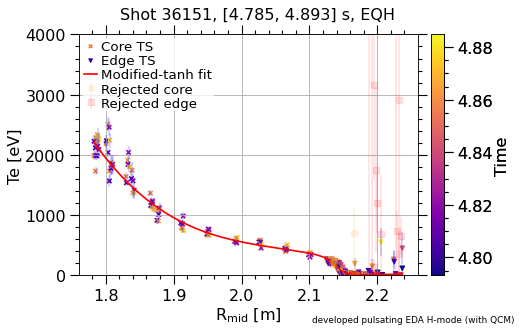

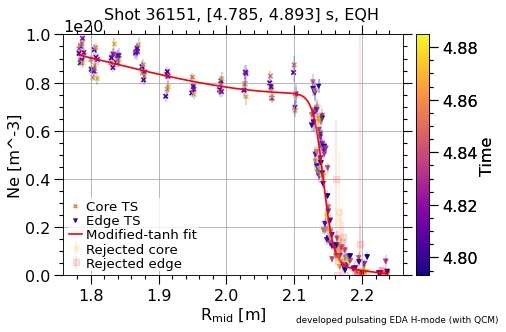

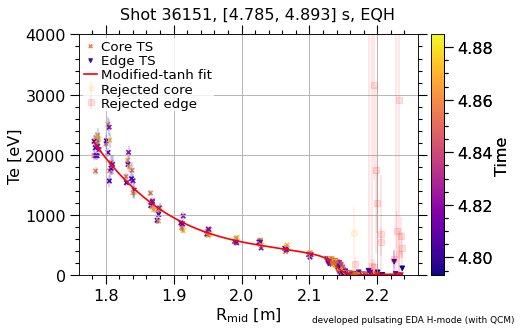

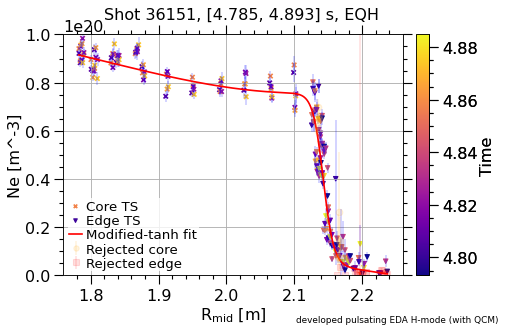

In [ ]:
for strategy_name in profile_runs:
    for quantity in ('Te', 'Ne'):
        plot_strategy_profile(
            strategy_name,
            quantity,
            show_fit=True,
            suffix='full',
            limits = {'y_maxs': 4000 if quantity == 'Te' else 1e20, 'y_mins': 0}
        )

## Zoom Profiles

Edit the axis-limit values below for each quantity. Set `zoom_show_fit` to `False` for data-only views or `True` to include the fit curve.

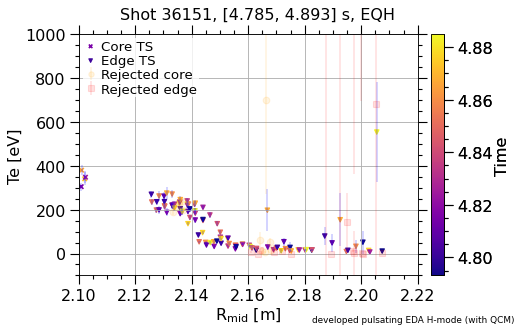

/tmp/ipykernel_26779/3151784897.py:29: UserWarning: not plotting dataset 1 due to ValueError: ('zero-size array to reduction operation fmax which has no identity',)
  return plot_profile_fit(


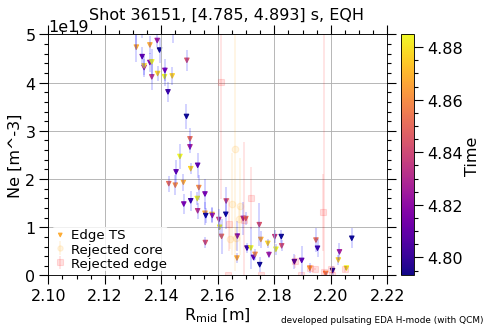

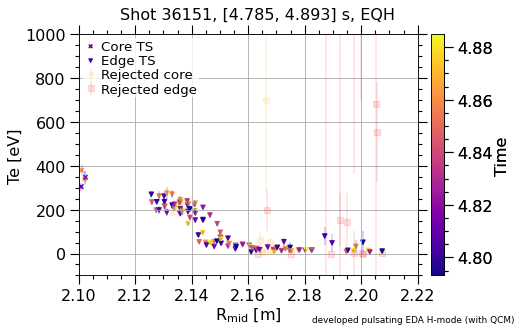

/tmp/ipykernel_26779/3151784897.py:29: UserWarning: not plotting dataset 1 due to ValueError: ('zero-size array to reduction operation fmax which has no identity',)
  return plot_profile_fit(


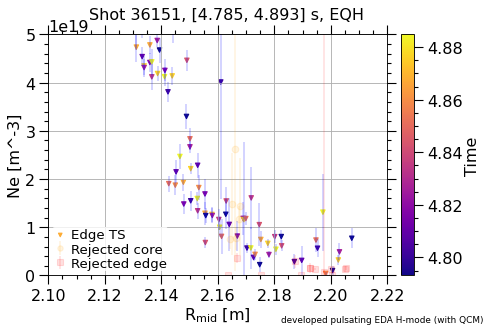

In [ ]:
zoom_axis_limits = {
    'Te': {
        'x_mins': 2.10,
        'x_maxs': 2.22,
        'y_mins': -100,
        'y_maxs': 1000,
    },
    'Ne': {
        'x_mins': 2.10,
        'x_maxs': 2.22,
        'y_mins': 0,
        'y_maxs': 5e19,
    },
}
zoom_show_fit = False

for strategy_name in profile_runs:
    for quantity in ('Te', 'Ne'):
        plot_strategy_profile(
            strategy_name,
            quantity,
            limits=zoom_axis_limits[quantity],
            show_fit=zoom_show_fit,
            suffix='zoom',
        )